## Objetivo 3: Modelo predictivo de coste de seguro




### Cargo los atos y las librerías



In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.model_selection import KFold
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


datos = pd.read_csv("Prestamos_educacion_limpio.csv")
prob_train = pd.read_csv("prob_impago_test.csv")
prob_test = pd.read_csv("prob_impago_test.csv")

train=prob_train.merge(datos, on='ID')
test=prob_test.merge(datos, on='ID')

Miramos la distribución de la variable Prima antes de entrenarla


,Prima,Prob_Impago
count,35722.00,35722.00
mean,386.61,0.12
std,266.89,0.07
min,10.00,0.01
25%,140.49,0.06
50%,339.03,0.10
75%,618.66,0.15
max,800.00,0.58


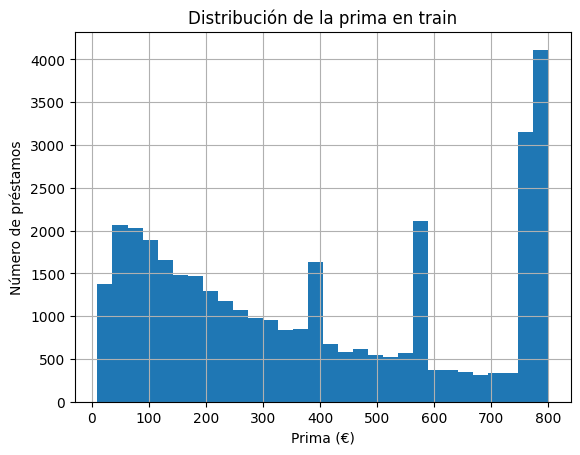

In [2]:
display(train[["Prima", "Prob_Impago"]].describe().round(2))

train["Prima"].hist(bins=30)
plt.title("Distribución de la prima en train")
plt.xlabel("Prima (€)")
plt.ylabel("Número de préstamos")
plt.show()


La concentración de préstamos con primas altas podría influir en las predicciones. Por eso no elegiremos el modelo solo mirando esta gráfica: compararemos la regresión lineal y la polinómica y comprobaremos cuál comete menos error en los datos de test.

Quitamos Impago e Impago_real de las variables que usaremos para predecir, porque ya tenemos Prob_Impago, que conserva la probabilidad estimada. Después calculamos la frecuencia de cada categoría dummy y quitamos la más frecuente de cada grupo para dejarla como referencia.

In [3]:
columnas_fuera = ["ID", "Impago_real", "Impago", "Prima"]

X_train = train.drop(columns=columnas_fuera)
y_train = train["Prima"]

X_test = test.drop(columns=columnas_fuera)
y_test = test["Prima"]

### Regresión lineal

Hemos ajustado una regresión lineal múltiple para estimar la prima usando las características del préstamo y prob_impago. El modelo calcula cómo se relaciona cada variable con la prima. Después miramos los p-valores para identificar qué variables son significativas y simplificar el modelo antes de probar la regresión polinómica.

In [4]:
escalador = StandardScaler()

X_train_escalado = pd.DataFrame(
    escalador.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_escalado = pd.DataFrame(
    escalador.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

modelo = sm.OLS(y_train, sm.add_constant(X_train_escalado)).fit()

p_valores = modelo.pvalues.drop("const")
display(p_valores.sort_values().round(4))

Monto_Inicial                            0.0000
Scoring_Crediticio                       0.0000
Ratio_Deuda_Ingresos                     0.0000
Duracion                                 0.0000
Ratio_Interes                            0.0000
Prob_Impago                              0.0000
Ingresos                                 0.0000
Estudios_encoded                         0.0000
Meses_Empleo                             0.0038
Estado_Civil_Soltero                     0.0540
Tipo_Jornada_Laboral_Jornada completa    0.4681
Tipo_Jornada_Laboral_Desempleado         0.5508
Edad                                     0.5534
Fiador                                   0.5962
Num_Creditos                             0.6712
Tipo_Jornada_Laboral_Tiempo parcial      0.7349
Posesion_Hipoteca                        0.7856
Estado_Civil_Divorciado                  0.8677
Personas_Cargo                           0.8711
dtype: float64

En la primera regresión lineal hemos mirado los p-valores y hemos usado 0,05 como límite. Las variables que lo superan no muestran suficiente evidencia de relación con la prima dentro de este modelo, así que las quitamos y repetimos la regresión con las demás. Esto no significa que nunca tengan relación, sino que aquí no resultan significativas.

In [5]:
variables_fuera = p_valores[p_valores > 0.05].index.tolist()
print(variables_fuera)

X_train_reducido = X_train_escalado.drop(columns=variables_fuera)
X_test_reducido = X_test_escalado.drop(columns=variables_fuera)

modelo_reducido = sm.OLS(
    y_train,
    sm.add_constant(X_train_reducido)
).fit()

p_valores_reducido = modelo_reducido.pvalues.drop("const")
display(p_valores_reducido.sort_values().round(4))

['Edad', 'Num_Creditos', 'Posesion_Hipoteca', 'Personas_Cargo', 'Fiador', 'Estado_Civil_Divorciado', 'Estado_Civil_Soltero', 'Tipo_Jornada_Laboral_Desempleado', 'Tipo_Jornada_Laboral_Jornada completa', 'Tipo_Jornada_Laboral_Tiempo parcial']


Scoring_Crediticio      0.0
Monto_Inicial           0.0
Duracion                0.0
Ratio_Deuda_Ingresos    0.0
Ratio_Interes           0.0
Prob_Impago             0.0
Ingresos                0.0
Estudios_encoded        0.0
Meses_Empleo            0.0
dtype: float64

Las variables de la lista son las que hemos quitado porque su p-valor era mayor que 0,05. En la tabla aparecen las que hemos dejado; como sus p-valores son menores que 0,05, se consideran significativas dentro de esta regresión. 

Ahora comprobaremos si esta regresión predice bien la prima en los datos de test.

In [6]:
predicciones = modelo_reducido.predict(sm.add_constant(X_test_reducido))

print("MAE:", round(mean_absolute_error(y_test, predicciones), 2))
print("RMSE:", round(mean_squared_error(y_test, predicciones) ** 0.5, 2))
print("R²:", round(r2_score(y_test, predicciones), 3))

MAE: 120.31
RMSE: 152.11
R²: 0.675


### Resultados de la regresión lineal

En los datos de test, el error medio de las predicciones es de unos 120,31€ (MAE). El RMSE es de 152,11€y da más peso a los errores grandes. El R indica que el modelo recoge aproximadamente el 67,5 % de las diferencias en las primas.

Ahora vamos a comparar estos resultados con lo de la regresión polinómica; cuanto menores sean el MAE y el RMSE, y mayor el R², mejor será el ajuste.

### Regresión polinómica

Para esta parte seleccionamos las 9 variables con menor p-valor de la regresión lineal reducida. Así usamos las variables que mejor encajan en el modelo y evitamos incluir las que ya habíamos quitado.

Después comparamos los grados 3, 4 y 5 con validación cruzada de cinco partes. El conjunto de test queda reservado para comprobar el resultado final.

In [7]:
variables_polinomicas = p_valores_reducido.sort_values().head(9).index.tolist()
X_base = X_train_reducido[variables_polinomicas].to_numpy()

In [8]:
variables_polinomicas = p_valores_reducido.sort_values().head(9).index.tolist()
X_base = X_train_reducido[variables_polinomicas].to_numpy()

In [9]:
y = y_train.to_numpy()
cv = KFold(n_splits=5, shuffle=True, random_state=42)
resultados = []

for grado in [3, 4, 5]:
    errores_rmse = []
    errores_mae = []
    valores_r2 = []

    for indice_train, indice_validacion in cv.split(X_base):
        X_tr = X_base[indice_train]
        X_val = X_base[indice_validacion]
        y_tr = y[indice_train]
        y_val = y[indice_validacion]

        polinomio = PolynomialFeatures(degree=grado, include_bias=False)
        X_tr_poly = polinomio.fit_transform(X_tr)
        X_val_poly = polinomio.transform(X_val)

        modelo_poly = LinearRegression()
        modelo_poly.fit(X_tr_poly, y_tr)
        predicciones = modelo_poly.predict(X_val_poly)
        predicciones = np.clip(predicciones, 0, 800)

        errores_rmse.append(mean_squared_error(y_val, predicciones) ** 0.5)
        errores_mae.append(mean_absolute_error(y_val, predicciones))
        valores_r2.append(r2_score(y_val, predicciones))

    resultados.append({
        "Grado": grado,
        "RMSE": np.mean(errores_rmse),
        "MAE": np.mean(errores_mae),
        "R²": np.mean(valores_r2)
    })

tabla_resultados = pd.DataFrame(resultados).sort_values("RMSE")
display(tabla_resultados.round(2))

,Grado,RMSE,MAE,R²
2,5,60.55,42.18,0.95
1,4,63.18,45.05,0.94
0,3,71.59,51.78,0.93


### Resultados de la regresión polinómica

El grado 5 da los mejores resultados de los tres probados. Su RMSE es de 60,55€ y su MAE es de 42,18€. Ambos miden el error de las predicciones en euros; el RMSE penaliza más los errores grandes. El R² es 0,95, lo que indica que el modelo recoge gran parte de las diferencias entre las primas.

Sin embargo, podemos observar que no hay una gran diferencia en los errores calculados con el grado 3 y con el grado 5, y en la explicación de la variabilidad; por lo que me voy a quedar con el grado 3, ya que así será mucho más facil de explicarlo.

### Evaluación final

Despues de realizar la validación cruzada hemos decidido quedarnos con el grado 3. Ahora lo ajustamos con todos los datos de entrenamiento y comparamos su resultado en test con el de la regresión lineal. En la tabla veremos cuál predice mejor las primas.

In [10]:
grado_elegido = 3

polinomio_final = PolynomialFeatures(
    degree=grado_elegido,
    include_bias=False
)

X_train_poly = polinomio_final.fit_transform(
    X_train_reducido[variables_polinomicas].to_numpy()
)

X_test_poly = polinomio_final.transform(
    X_test_reducido[variables_polinomicas].to_numpy()
)

modelo_polinomico = LinearRegression()
modelo_polinomico.fit(X_train_poly, y_train)

pred_polinomica = modelo_polinomico.predict(X_test_poly)
pred_lineal = modelo_reducido.predict(sm.add_constant(X_test_reducido))

comparacion = pd.DataFrame({
    "Modelo": ["Lineal", "Polinómico grado 3"],
    "RMSE": [
        mean_squared_error(y_test, pred_lineal) ** 0.5,
        mean_squared_error(y_test, pred_polinomica) ** 0.5
    ],
    "MAE": [
        mean_absolute_error(y_test, pred_lineal),
        mean_absolute_error(y_test, pred_polinomica)
    ],
    "R²": [
        r2_score(y_test, pred_lineal),
        r2_score(y_test, pred_polinomica)
    ]
})

display(comparacion.round(2))


,Modelo,RMSE,MAE,R²
0,Lineal,152.11,120.31,0.68
1,Polinómico grado 3,74.72,55.77,0.92


La regresión polinómica de grado 3 funciona mejor que la lineal en los datos de test. Su error medio es de 55,77 €, frente a los 120,31 € de la regresión lineal. Además, su RMSE es menor y su R² es mayor (0,92 frente a 0,68).

Por estos resultados, elegimos la regresión polinómica de grado 3 para estimar la prima del seguro.

### Revisión de las predicciones

Comprobamos si el modelo estima primas por encima del máximo observado en los datos de test.

In [11]:
print("Máxima prima real:", y_test.max())
print("Máxima prima estimada:", pred_polinomica.max())
print("Predicciones por encima del máximo real:",
      (pred_polinomica > y_test.max()).sum())

Máxima prima real: 800.0
Máxima prima estimada: 1283.5857544541336
Predicciones por encima del máximo real: 2063


Nos da que hay muchísimas predicciones por encima del máximo real, esto es algo negativo para nuestro  modelo, ya que el cliente pide que la máxima prima real sea de un total de 800; sin embargo, no hemos limitado el entrenamiento a 800, ya que sino prediciría mal luego, ya que habría muchísimas máximas primas estimadas de 800, lo que les daría bastante mas importancia.

Realizamos un gráfico para comparar las primas reales con las estimadas

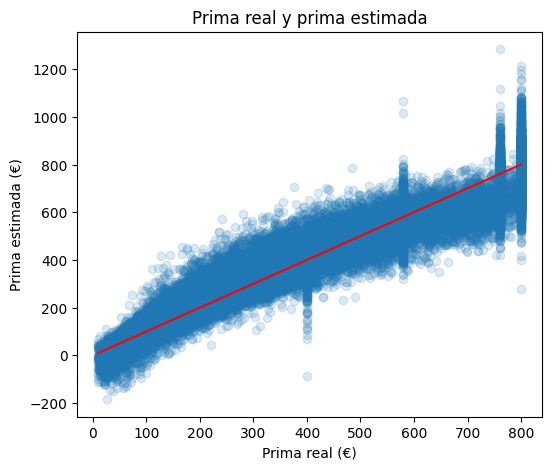

In [12]:
limites = [y_test.min(), y_test.max()]
plt.figure(figsize=(6, 5))
plt.scatter(y_test, pred_polinomica, alpha=0.15)
plt.plot(limites, limites, color="red")
plt.title("Prima real y prima estimada")
plt.xlabel("Prima real (€)")
plt.ylabel("Prima estimada (€)")
plt.show()


La línea roja representa las predicciones perfectas: los puntos cercanos a ella tienen menos error. Aunque la mayoría siguen una tendencia similar, hay algunos casos en los que el modelo sobreestima mucho la prima.